# Chapitre 1 - Cours 4 : la pile de l'AI engineering

Ce dernier notebook de cours accompagne la section *The AI Engineering Stack* du
chapitre 1 : les trois couches de toute application d'IA (*Three Layers of the AI
Stack*), ce qui distingue l'AI engineering du ML engineering classique (*AI Engineering
Versus ML Engineering*, avec ses sous-parties *Model development* et *Application
development*) et son rapprochement avec le développement full-stack (*AI Engineering
Versus Full-Stack Engineering*).

Plan :

1. les trois couches de la pile ;
2. ce qui ne change pas : métriques et expérimentation systématique (une vraie grille
   d'expériences sur des prompts) ;
3. AI engineering contre ML engineering : adapter plutôt qu'entraîner, des modèles plus
   gros, des sorties ouvertes ;
4. la couche développement de modèle (entraînement, données, optimisation de l'inférence) ;
5. la couche développement d'application (évaluation, prompt, interface) ;
6. AI engineering contre développement full-stack : le flux de travail inversé.

In [1]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 120)

## 1. Les trois couches de la pile (section *Three Layers of the AI Stack*)

Face à l'avalanche quotidienne d'outils, de techniques et de modèles, le livre propose de
revenir aux briques fondamentales. Toute application d'IA repose sur trois couches :

- **développement d'application** : fournir au modèle de bons prompts et le contexte
  nécessaire, évaluer rigoureusement, construire une bonne interface. C'est la couche qui
  a connu le plus d'activité depuis l'arrivée des modèles de fondation ;
- **développement de modèle** : outils pour modéliser, entraîner, finetuner, optimiser
  l'inférence, et l'ingénierie des jeux de données ; l'évaluation y est aussi centrale ;
- **infrastructure** : servir les modèles, gérer données et calcul, surveiller.

On commence en général par la couche du haut, et on ne descend que si nécessaire.

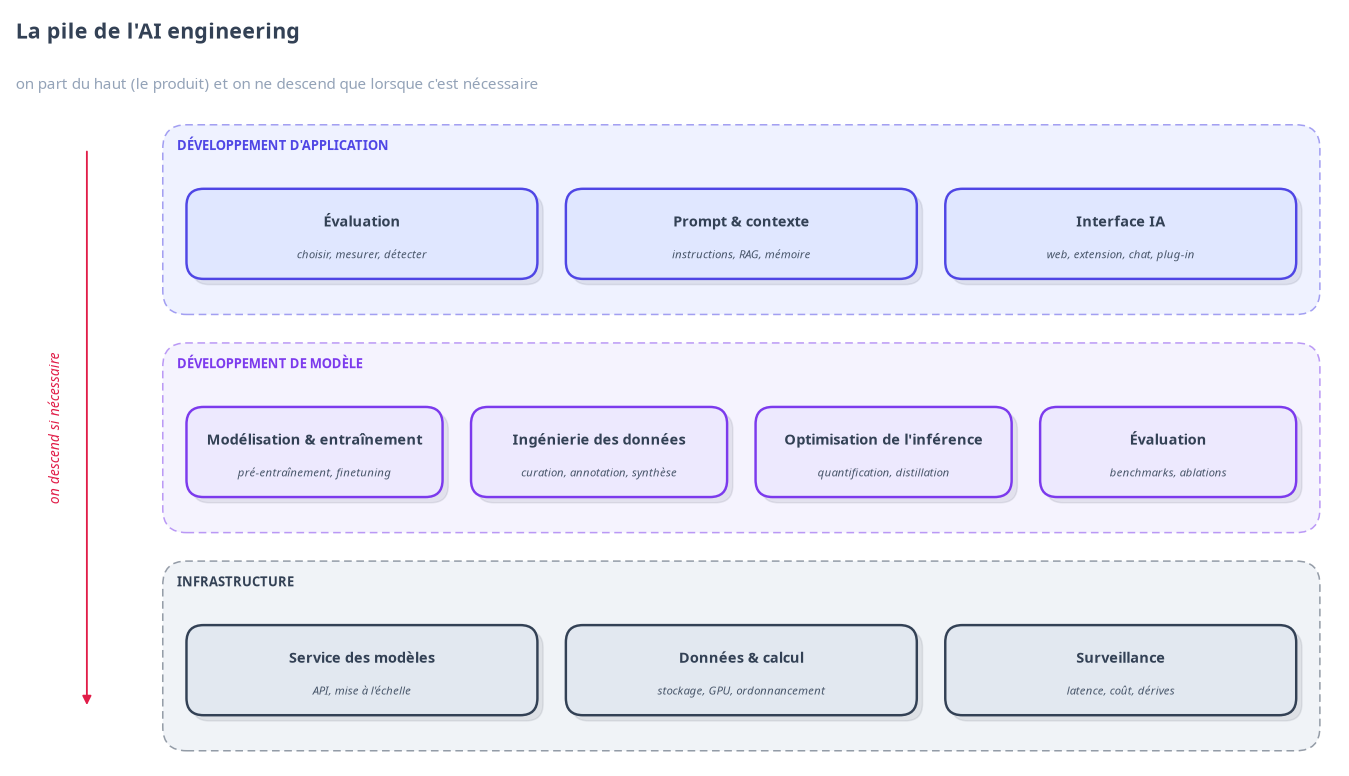

In [2]:
d = Diagram(14, 7.0, title="La pile de l'AI engineering",
            subtitle="on part du haut (le produit) et on ne descend que lorsque c'est nécessaire")
layers = [
    ("Développement d'application", INDIGO, 5.75,
     [("Évaluation", "choisir, mesurer, détecter"), ("Prompt & contexte", "instructions, RAG, mémoire"),
      ("Interface IA", "web, extension, chat, plug-in")]),
    ("Développement de modèle", VIOLET, 3.45,
     [("Modélisation & entraînement", "pré-entraînement, finetuning"), ("Ingénierie des données", "curation, annotation, synthèse"),
      ("Optimisation de l'inférence", "quantification, distillation"), ("Évaluation", "benchmarks, ablations")]),
    ("Infrastructure", SLATE, 1.15,
     [("Service des modèles", "API, mise à l'échelle"), ("Données & calcul", "stockage, GPU, ordonnancement"),
      ("Surveillance", "latence, coût, dérives")]),
]
for name, col, yc, items in layers:
    d.group(1.6, yc - 1.0, 13.8, yc + 1.0, name, col, alpha=0.5)
    n = len(items)
    w = (11.7 - 0.3 * (n - 1)) / n           # marge intérieure de 0,25 de chaque côté
    for i, (t, sub) in enumerate(items):
        x = 1.85 + w / 2 + i * (w + 0.3)
        d.box(f"{name}{i}", x, yc - 0.15, t, sub=sub, color=col, w=w, h=0.95, fontsize=9.5)
d.line([(0.8, 6.5), (0.8, 0.6)], color=ROSE, style="solid")
d.note(0.45, 3.55, "on descend si nécessaire", color=ROSE, fontsize=9)
d.ax.texts[-1].set_rotation(90)
d.show()

Le livre observe, en recensant les dépôts GitHub d'IA les plus populaires, une explosion
des outils de **développement d'application** (et des applications elles-mêmes) en 2023,
après Stable Diffusion et ChatGPT, tandis que la couche **infrastructure** a beaucoup
moins bougé : les besoins fondamentaux (gérer des ressources, servir, surveiller) restent
les mêmes, quel que soit le modèle.

> **À retenir.** Trois couches : application (prompt, contexte, évaluation, interface),
> modèle (entraînement, données, inférence, évaluation), infrastructure (service, calcul,
> surveillance). L'AI engineering commence en haut de la pile.

## 2. Ce qui ne change pas : métriques et expérimentation systématique (section *Three Layers of the AI Stack*)

Malgré l'effervescence, beaucoup de principes du ML engineering restent valables : une
application d'entreprise doit résoudre un problème métier, donc il faut relier métriques
métier et métriques de ML ; il faut **expérimenter systématiquement** (on ne règle plus
des hyperparamètres d'entraînement, mais des modèles, des prompts, des algorithmes de
recherche, des paramètres d'échantillonnage) ; il faut des modèles plus rapides et moins
chers ; et une boucle de retour avec les données de production.

**Une vraie grille d'expériences.** Classons le sentiment de 16 avis courts rédigés pour
ce dépôt, avec Qwen2.5-0.5B, en croisant 3 formulations de prompt et 2 régimes
(zéro exemple, 3 exemples dans le prompt : *few-shot*).

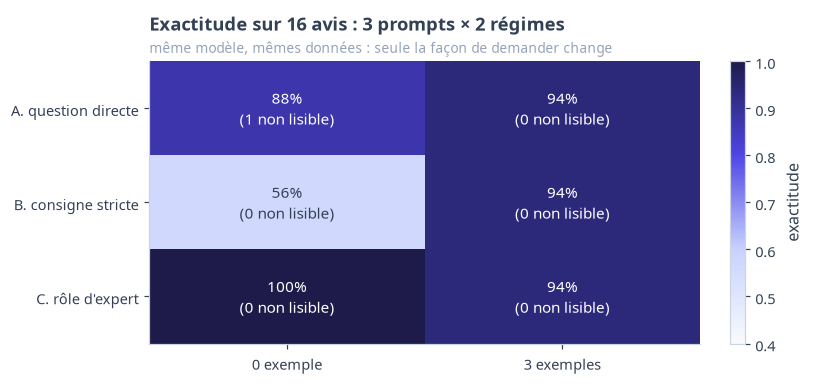

In [3]:
reviews = [
    ("Livraison en 24 h, produit conforme, je recommande.", "positif"),
    ("Le colis est arrivé ouvert et il manquait une pièce.", "négatif"),
    ("Très bon rapport qualité-prix, je rachèterai.", "positif"),
    ("Service client injoignable depuis deux semaines.", "négatif"),
    ("La batterie tient à peine une demi-journée.", "négatif"),
    ("Montage facile, notice claire, rien à redire.", "positif"),
    ("Taille trop petite, j'ai dû le renvoyer.", "négatif"),
    ("Superbe qualité, mes enfants l'adorent.", "positif"),
    ("Ça fait le travail, sans plus.", "négatif"),
    ("Remboursé rapidement après mon retour, merci.", "positif"),
    ("Odeur chimique très forte à l'ouverture.", "négatif"),
    ("Exactement comme sur les photos.", "positif"),
    ("Il est tombé en panne après trois jours.", "négatif"),
    ("Emballage soigné et petit mot manuscrit, adorable.", "positif"),
    ("Trop cher pour ce que c'est.", "négatif"),
    ("Le meilleur achat de l'année !", "positif"),
]
shots = [("Article reçu cassé, très déçu.", "négatif"), ("Parfait, rien à redire.", "positif"),
         ("Couleur différente de la photo, dommage.", "négatif")]
templates = {
    "A. question directe": "Cet avis est-il positif ou négatif ?\nAvis : {r}\nRéponse :",
    "B. consigne stricte": "Classe le sentiment de l'avis. Réponds uniquement par « positif » ou « négatif ».\nAvis : {r}",
    "C. rôle d'expert": "Tu es un analyste du service client. Indique si le client est satisfait (positif) ou insatisfait (négatif).\nAvis : {r}\nRéponds par un seul mot.",
}

def build_messages(tpl, r, k):
    msgs = []
    for sr, sl in shots[:k]:
        msgs += [{"role": "user", "content": tpl.format(r=sr)}, {"role": "assistant", "content": sl}]
    return msgs + [{"role": "user", "content": tpl.format(r=r)}]

def parse(ans):
    """Extrait l'étiquette d'une réponse libre ; « ? » si la réponse est inexploitable."""
    a = ans.lower()
    neg = any(w in a for w in ["négat", "negat", "insatisf"])
    pos = any(w in a for w in ["posit", "satisf"]) and not neg
    return "négatif" if neg else ("positif" if pos else "?")

acc = pd.DataFrame(index=list(templates), columns=["0 exemple", "3 exemples"], dtype=float)
unparsed = pd.DataFrame(0, index=list(templates), columns=acc.columns)
for name, tpl in templates.items():
    for k, col in [(0, "0 exemple"), (3, "3 exemples")]:
        preds = [parse(llm.chat(build_messages(tpl, r, k), llm.SMALL, max_new_tokens=24)) for r, _ in reviews]
        acc.loc[name, col] = np.mean([p == y for p, (_, y) in zip(preds, reviews)])
        unparsed.loc[name, col] = sum(p == "?" for p in preds)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(acc.values.astype(float), cmap="aie_seq", vmin=0.4, vmax=1.0, aspect="auto")
ax.set_xticks(range(2), acc.columns); ax.set_yticks(range(3), acc.index); ax.grid(False)
for i in range(3):
    for j in range(2):
        v = acc.values[i, j]
        ax.text(j, i, f"{v:.0%}\n({unparsed.values[i, j]} non lisible)", ha="center", va="center",
                color="white" if v > 0.75 else SLATE, fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.04, label="exactitude")
c1.title_sub(ax, "Exactitude sur 16 avis : 3 prompts × 2 régimes",
             "même modèle, mêmes données : seule la façon de demander change")
plt.tight_layout(); plt.show()

Sur un si petit jeu (16 avis), un écart de 6 points correspond à **un seul** avis : il faut
rester prudent dans les conclusions (le chapitre 4 traite de la taille des jeux
d'évaluation). Mais l'enseignement général tient. Sans exemple, la seule formulation fait
varier l'exactitude dans de grandes proportions, et la consigne qui paraît la plus
« propre » n'est pas forcément la meilleure : l'intuition ne remplace pas la mesure. Avec
trois exemples, les trois formulations convergent : les exemples montrent au modèle la
forme de réponse attendue et rendent le résultat bien moins sensible au libellé. Le cas
« Ça fait le travail, sans plus », que nous avons étiqueté négatif, est discutable : les
erreurs restantes révèlent aussi les ambiguïtés de nos propres étiquettes. D'où la règle
d'or : **comparer des modèles ou des versions dans des conditions de prompt identiques**,
et garder la trace de chaque configuration testée.

> **À retenir.** Les principes du ML engineering demeurent : relier métriques métier et
> métriques techniques, expérimenter systématiquement (désormais sur les prompts, les
> modèles, la recherche de contexte), optimiser coût et latence, boucler avec la production.

## 3. AI engineering contre ML engineering : trois différences (section *AI Engineering Versus ML Engineering*)

Le livre résume la différence en trois points :

1. **on adapte au lieu d'entraîner** : le modèle a été entraîné par quelqu'un d'autre ;
   l'effort porte sur l'adaptation, par le prompt (poids inchangés) ou par le finetuning
   (poids modifiés) ;
2. **les modèles sont plus gros**, consomment plus de calcul et ont une latence plus
   élevée : l'optimisation de l'entraînement et de l'inférence devient cruciale, et il
   faut savoir travailler avec des GPU et des grappes de calcul ;
3. **les sorties sont ouvertes** : plus de tâches possibles, mais une évaluation bien plus
   difficile.

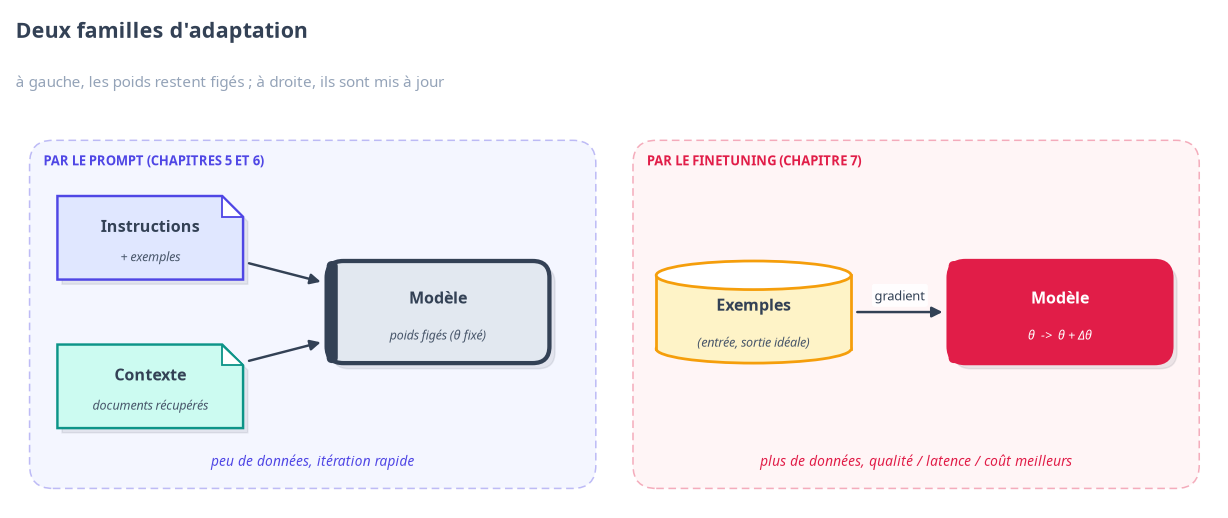

In [4]:
d = Diagram(13, 4.4, title="Deux familles d'adaptation", subtitle="à gauche, les poids restent figés ; à droite, ils sont mis à jour")
d.group(0.2, 0.2, 6.3, 3.95, "Par le prompt (chapitres 5 et 6)", INDIGO)
d.box("p_in", 1.5, 2.9, "Instructions", sub="+ exemples", color=INDIGO, kind="doc", w=2.0, h=0.9)
d.box("p_ctx", 1.5, 1.3, "Contexte", sub="documents récupérés", color=TEAL, kind="doc", w=2.0, h=0.9)
d.box("p_m", 4.6, 2.1, "Modèle", sub="poids figés (θ fixé)", color=SLATE, kind="model", w=2.4, h=1.1)
d.arrow("p_in", "p_m"); d.arrow("p_ctx", "p_m")
d.note(3.25, 0.5, "peu de données, itération rapide", color=INDIGO, fontsize=9)
d.group(6.7, 0.2, 12.8, 3.95, "Par le finetuning (chapitre 7)", ROSE)
d.box("f_d", 8.0, 2.1, "Exemples", sub="(entrée, sortie idéale)", color=AMBER, kind="db", w=2.1, h=1.1)
d.box("f_m", 11.3, 2.1, "Modèle", sub="θ  ->  θ + Δθ", color=ROSE, kind="model", w=2.4, h=1.1, filled=True)
d.arrow("f_d", "f_m", "gradient")
d.note(9.75, 0.5, "plus de données, qualité / latence / coût meilleurs", color=ROSE, fontsize=9)
d.show()

**Des modèles plus gros.** Mettons en regard des modèles « classiques » et des modèles de
fondation, en nombre de paramètres (ordres de grandeur typiques).

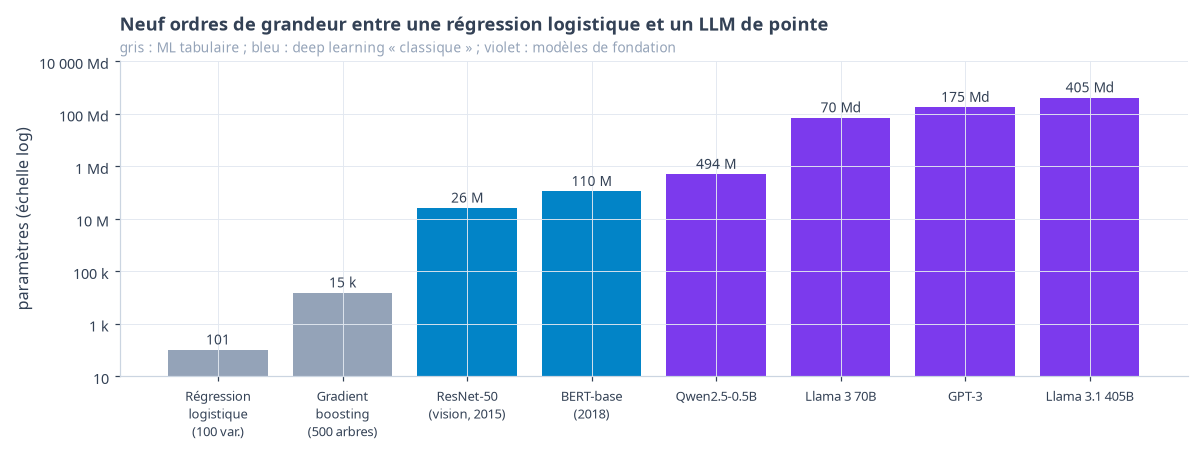

In [5]:
sizes = {"Régression\nlogistique\n(100 var.)": 101, "Gradient\nboosting\n(500 arbres)": 1.5e4,
         "ResNet-50\n(vision, 2015)": 25.6e6, "BERT-base\n(2018)": 110e6, "Qwen2.5-0.5B": 494e6,
         "Llama 3 70B": 70e9, "GPT-3": 175e9, "Llama 3.1 405B": 405e9}
fig, ax = plt.subplots(figsize=(11, 4.2))
cols = [GRAY, GRAY, SKY, SKY, VIOLET, VIOLET, VIOLET, VIOLET]
ax.bar(list(sizes), list(sizes.values()), color=cols)
ax.set_yscale("log"); c1.human_log(ax)
for i, v in enumerate(sizes.values()):
    ax.text(i, v * 1.6, c1.human_number(v), ha="center", fontsize=9)
ax.set_ylabel("paramètres (échelle log)")
ax.tick_params(axis="x", labelsize=8.5)
ax.set_ylim(10, 1e13)
c1.title_sub(ax, "Neuf ordres de grandeur entre une régression logistique et un LLM de pointe",
             "gris : ML tabulaire ; bleu : deep learning « classique » ; violet : modèles de fondation")
plt.tight_layout(); plt.show()

**Des sorties ouvertes.** Un classifieur de spam n'a que deux sorties possibles : on compare
à la vérité terrain et c'est fini. Demandez à un modèle génératif un nom de boulangerie,
et il existe une infinité de bonnes réponses. Échantillonnons 10 réponses (température
1,0, graines fixées) pour une même question.

In [6]:
q = "Propose un nom original pour une boulangerie de quartier. Réponds uniquement par le nom."
answers = [re.sub(r"[«»\"*.]", "", llm.chat(q, llm.SMALL, max_new_tokens=12, temperature=1.0, seed=s)).strip()
           for s in range(10)]
cnt = Counter(answers)
print(f"{len(cnt)} réponses distinctes sur {len(answers)} :")
for a_, n_ in cnt.most_common():
    print(f"  {n_} × {a_[:60]}")

10 réponses distinctes sur 10 :
  1 × Boulotte
  1 × Flora Boulangerie
  1 × Delice Delicata
  1 × La Boulangerie du Marché
  1 × Locum Bakery
  1 × Lampoonerie
  1 × Locale Boulangerie
  1 × Boulangeria
  1 × Epic Biscuit Shop
  1 × Cafe La Bocotte


Presque toutes les réponses sont différentes. Certaines sont bancales (un nom anglais, un
mot inventé peu heureux), plusieurs sont parfaitement acceptables : aucune liste de
« bonnes réponses » ne peut être exhaustive, et juger lesquelles sont « bonnes » demande
des critères explicites (originalité ? langue ? prononçabilité ?). On ne peut pas évaluer par simple égalité
avec une référence ; il faudra des critères, des juges (humains ou IA), des comparaisons
(chapitres 3 et 4). C'est pourquoi l'**évaluation** est le grand défi de l'AI engineering.

> **À retenir.** L'AI engineering, c'est moins de modélisation et plus d'**adaptation** et
> d'**évaluation** ; avec des modèles plus gros (calcul, latence) aux sorties ouvertes
> (évaluation difficile).